# 🐱🚗 FarmTech Solutions — Ir Além 2 · Parte 2: Segmentação e máscaras

**FIAP · Fase 6 · PBL — "Ir Além", Opção 2 (Transfer Learning, Fine Tuning e Segmentação)**

Integrantes: Victor Vergara Koshikene (RM 568813) · Leonardo Lima de Queiroz (RM 573539) · Vinicius Prado Speria
(RM 572741) · Leonardo Ribeiro de Souza (RM 571534) · Matheus Costa Manzoli Machado (RM 571814)

---

## Objetivo

Preparar a segunda abordagem do enunciado: **pré-segmentar o objeto de interesse** para que o classificador
olhe só para os pixels relevantes. Para cada imagem:

1. uma **rede de segmentação** gera a máscara do objeto (gato ou carro), de forma automática;
2. a máscara é aplicada na imagem original e o **fundo é apagado** (pixels pretos);
3. a imagem recortada segue para os classificadores no notebook 03.

A hipótese (**H2**) é testada no notebook 03: *pré-segmentar o objeto facilita a classificação?*

## Sumário

1. Configuração do ambiente
2. Dados
3. Escolha da rede de segmentação
4. Seleção do segmentador no treino + validação
5. Segmentação de todas as imagens e política de falha
6. Original | máscara | recortada
7. Onde a segmentação erra
8. O segmentador sozinho já classifica?
9. Atalho da área da máscara
10. Latência da segmentação
11. Ablação: YOLO da Entrega 1 → SAM 2.1
12. Conclusões da etapa

## 1. Configuração do ambiente

Este notebook usa só PyTorch (pacote `ultralytics`); o Keras não é importado aqui.

In [1]:
# ---------------- Configuração do ambiente ----------------
import os, shutil, subprocess, sys, time, json
from pathlib import Path

NO_COLAB = "google.colab" in sys.modules
URL_REPO = "https://github.com/koshivv/fiap-farmtech_solutions-fase06.git"

if NO_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                              # dados e pesos persistem entre sessões
    REPO_DIR = Path("/content/fiap-farmtech_solutions-fase06")
    if (REPO_DIR / "ir_alem_opcao2").exists():                 # sessão já tinha o clone: traz correções
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "-q", "--ff-only"], check=False)
    else:                                                      # main após o merge do PR; antes, o ramo do Ir Além
        shutil.rmtree(REPO_DIR, ignore_errors=True)
        for ramo in (os.environ.get("FARMTECH_RAMO", "main"), "ir-alem-opcao2"):
            subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", ramo, URL_REPO, str(REPO_DIR)], check=False)
            if (REPO_DIR / "ir_alem_opcao2").exists():
                break
            shutil.rmtree(REPO_DIR, ignore_errors=True)
    # Versão fixada: a API de máscaras/SAM do ultralytics mudou entre versões
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.175", "pycocotools"], check=True)
else:                                                          # local: sobe até achar a raiz do repositório
    REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ir_alem_opcao2" / "src").is_dir())

sys.path.insert(0, str(REPO_DIR / "ir_alem_opcao2"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from src import ambiente, config, dados, metricas, segmentacao, visualizacao as vis

config.garantir_pastas()
vis.aplicar_estilo()
AMBIENTE = ambiente.descrever_ambiente()
for chave, valor in AMBIENTE.items():
    print(f"{chave:18s}: {valor}")

python            : 3.11.9
colab             : False
keras_backend     : None
commit            : e5be53f
keras             : 3.13.2
torch             : 2.14.1
jax               : 0.10.2
ultralytics       : 8.4.175
numpy             : 2.4.6
pandas            : 3.0.6
scikit-learn      : 1.9.1
gpu_torch         : False


## 2. Dados

Mesmas imagens do notebook 01: as 85 das Entregas 1 e 2 e as 52 do teste ampliado. As **máscaras GT do COCO**
(polígonos anotados por humanos, presentes em todas as imagens) servem **só para avaliar** a segmentação e para
a condição "oráculo" do notebook 03; nunca entram no pipeline automático.

In [2]:
# ---------------- Tabela das imagens ----------------
coco = dados.carregar_coco()
tabela = dados.tabela_imagens(coco)                            # 85 originais + 52 do teste ampliado
falhas = dados.baixar_imagens(tabela)
assert not falhas, f"Falha no download: {falhas}"
GT = {a: dados.mascara_gt(coco, i) for a, i in zip(tabela.arquivo, tabela.coco_id)}
display(pd.crosstab(tabela.conjunto, tabela.grupo, margins=True, margins_name="total"))

loading annotations into memory...

Done (t=0.67s)
creating index...
index created!


grupo,carro,gato,mista,total
conjunto,,,,
teste_ampliado,26,26,0,52
teste_original,4,4,1,9
treino,32,32,3,67
validacao,4,4,1,9
total,66,66,5,137


## 3. Escolha da rede de segmentação

**Gato e carro são classes do COCO** (índices 15 e 2 na lista de 80 classes; `category_id` 17 e 3). Por isso
redes de segmentação pré-treinadas no COCO funcionam sem nenhum treino adicional. As opções avaliadas no
planejamento:

| Opção | Prós | Contras |
|---|---|---|
| **(a) YOLO-seg pré-treinado no COCO** (YOLO11-seg, YOLO26-seg; pacote `ultralytics`) | automático, rápido, máscara por instância; pesos treinados no COCO *train2017*, e nossas imagens são do *val2017* (que a Ultralytics usa como validação para escolher os pesos: IoU e acurácia implícita podem ser levemente otimistas) | conhece as classes: precisa descartar a classe prevista para não "classificar pelo classificador" |
| **(b) Caixas de um detector → SAM 2.1** (Segment Anything) | o SAM é agnóstico de classe e gera bordas finas a partir de uma caixa | dois modelos; a qualidade depende da caixa |
| (b') Caixas da **YOLO da Entrega 1** → SAM 2.1 | reaproveita o projeto | o detector foi treinado no nosso split de treino: caixas melhores no treino que no teste (ver Seção 11) |
| (c) DeepLabV3 / U-Net | DeepLab tem versão em Keras (KerasHub) | segmentação semântica, mais grosseira; U-Net exigiria treinar com poucas máscaras |
| (d) Saliência (BASNet, rembg) | não usa classes | em 35 das 76 imagens de treino + validação o maior objeto anotado **não** é o alvo (pessoa, laptop, caminhão, ônibus, sofá, moto) |

**Regras para não vazar o rótulo para o classificador:**

- o segmentador decide *quais pixels* ficam; a **classe que ele prevê é descartada**;
- a máscara é a **união** de todas as instâncias detectadas no conjunto de classes fixado, igual para gatos e carros;
- a **política de falha** é a mesma para as duas classes: sem detecção ou máscara < 1% da imagem → nova tentativa
  com confiança 0,10 → se falhar de novo, a imagem **original** segue para o classificador (fallback), e a falha é contada;
- o segmentador é escolhido **só com treino + validação**, pelo maior IoU médio contra a máscara GT (falha conta
  como IoU 0); empate (diferença ≤ 0,01) → menos falhas → conjunto estrito antes do amplo → modelo mais simples
  (YOLO26n-seg, YOLO11s-seg, YOLO26n-seg + SAM 2.1). O tempo por imagem é reportado, mas não decide (depende do hardware).

## 4. Seleção do segmentador no treino + validação

Candidatos: YOLO11s-seg, YOLO26n-seg e caixas do YOLO26n-seg refinadas pelo SAM 2.1-b, cada um com dois conjuntos de
classes: **estrito** {cat, car} e **amplo** (todos os veículos e animais do COCO). O amplo existe porque um gato
pode sair como "dog" ou um carro como "truck"; como a classe é descartada, isso não importa, mas o objeto entra na máscara.

In [3]:
# ---------------- Avaliação dos candidatos (treino + validação: 76 imagens) ----------------
selecao = tabela[tabela.conjunto.isin(["treino", "validacao"])]
imagens_selecao = {a: dados.abrir_imagem(config.IMAGENS_DIR / a) for a in selecao.arquivo}   # leitura fora do cronômetro
CONJUNTOS_CLASSES = {"estritas": config.CLASSES_SEG_ESTRITAS, "amplas": config.CLASSES_SEG_AMPLAS}
SIMPLICIDADE = {"yolo26n-seg": 0, "yolo11s-seg": 1, "yolo26n-seg+sam2.1_b": 2}   # desempate: mais simples primeiro
linhas = []
for nome in segmentacao.CANDIDATOS:
    for rotulo, classes in CONJUNTOS_CLASSES.items():
        seg = segmentacao.Segmentador(nome, classes)
        segmentacao.segmentar(seg, next(iter(imagens_selecao.values())))   # aquecimento (não cronometrado)
        ious, status, inicio = [], [], time.perf_counter()
        for arquivo, img in imagens_selecao.items():
            r = segmentacao.segmentar(seg, img)
            mascara = r.mascara if r.mascara is not None else np.zeros_like(GT[arquivo])
            ious.append(segmentacao.iou(mascara, GT[arquivo]))
            status.append(r.status)
        linhas.append({"segmentador": nome, "classes": rotulo, "IoU médio": np.mean(ious),
                       "IoU mediano": np.median(ious), "IoU mínimo": np.min(ious),
                       "falhas": status.count("falha"), "conf. reduzida": status.count("ok_conf_reduzida"),
                       "s/imagem": (time.perf_counter() - inicio) / len(selecao)})
        print(f"{nome:22s} {rotulo:9s} IoU médio {np.mean(ious):.3f}")
candidatos = pd.DataFrame(linhas)
candidatos.to_csv(config.RESULTADOS_DIR / "segmentacao_candidatos.csv", index=False)

# Regra de decisão fixada antes: maior IoU; empate (≤ 0,01) -> menos falhas -> estritas -> modelo mais simples
melhor_iou = candidatos["IoU médio"].max()
empatados = candidatos[candidatos["IoU médio"] >= melhor_iou - 0.01].assign(
    _classes=lambda d: d.classes.map({"estritas": 0, "amplas": 1}), _simples=lambda d: d.segmentador.map(SIMPLICIDADE))
escolhido = empatados.sort_values(["falhas", "_classes", "_simples"]).iloc[0]
ESCOLHA = {"segmentador": escolhido.segmentador, "classes": escolhido.classes}
(config.RESULTADOS_DIR / "segmentador_escolhido.json").write_text(json.dumps(ESCOLHA))
display(candidatos.round(3).set_index(["segmentador", "classes"]))
print("✅ Segmentador escolhido:", ESCOLHA)

yolo11s-seg            estritas  IoU médio 0.805


yolo11s-seg            amplas    IoU médio 0.714


yolo26n-seg            estritas  IoU médio 0.784


yolo26n-seg            amplas    IoU médio 0.680


yolo26n-seg+sam2.1_b   estritas  IoU médio 0.791


yolo26n-seg+sam2.1_b   amplas    IoU médio 0.688


IoU médio  IoU mediano  IoU mínimo  falhas  \
segmentador          classes                                                
yolo11s-seg          estritas      0.805        0.906       0.000       5   
                     amplas        0.714        0.870       0.145       0   
yolo26n-seg          estritas      0.784        0.906       0.000       6   
                     amplas        0.680        0.833       0.000       4   
yolo26n-seg+sam2.1_b estritas      0.791        0.915       0.000       6   
                     amplas        0.688        0.844       0.000       4   

                               conf. reduzida  s/imagem  
segmentador          classes                             
yolo11s-seg          estritas               2     0.419  
                     amplas                 2     0.401  
yolo26n-seg          estritas               4     0.232  
                     amplas                 1     0.178  
yolo26n-seg+sam2.1_b estritas               4     6.191  
                     amplas                 1     5.224

✅ Segmentador escolhido: {'segmentador': 'yolo11s-seg', 'classes': 'estritas'}


## 5. Segmentação de todas as imagens e política de falha

Com o segmentador fixado, processamos as 137 imagens (85 das Entregas + 52 do teste ampliado) e gravamos três
versões de cada uma, usadas no notebook 03:

| Condição | O que é | Papel |
|---|---|---|
| **segmentada (S)** | fundo apagado (preto), mesmo enquadramento da original | condição principal da H2 |
| recorte (C) | segmentada e recortada pela caixa da máscara (+10% de folga) | ablação: separa "apagar o fundo" de "ampliar o objeto" |
| oráculo (G) | fundo apagado com a máscara **GT** do COCO (anotação humana) | referência: estima quanto a H2 ganharia com uma segmentação próxima da perfeita (não é um teto garantido: os polígonos do COCO são grosseiros) |

Quando a segmentação falha, as condições S e C recebem a imagem original (fallback).

In [4]:
# ---------------- Segmentação final ----------------
seg = segmentacao.Segmentador(ESCOLHA["segmentador"], CONJUNTOS_CLASSES[ESCOLHA["classes"]])
pasta_mascaras = config.MASCARAS_DIR / ESCOLHA["segmentador"]
registros, inicio = [], time.perf_counter()
for linha in tabela.itertuples():
    img = dados.abrir_imagem(config.IMAGENS_DIR / linha.arquivo)
    original = np.asarray(img)
    r = segmentacao.segmentar(seg, img)
    png = Path(linha.arquivo).with_suffix(".png").name
    if r.mascara is not None:
        segmentacao.salvar_mascara(r.mascara, pasta_mascaras / png)
        segmentada = segmentacao.aplicar_mascara(original, r.mascara)
        recorte = segmentacao.recortar_pela_mascara(segmentada, r.mascara)
    else:                                                      # fallback: imagem original nas condições S e C
        segmentada = recorte = original
    oraculo = segmentacao.aplicar_mascara(original, GT[linha.arquivo])
    for condicao, imagem in (("segmentada", segmentada), ("recorte", recorte), ("oraculo", oraculo)):
        destino = config.CONDICOES_DIR / condicao / png
        destino.parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(imagem).save(destino)
    mascara = r.mascara if r.mascara is not None else np.zeros_like(GT[linha.arquivo])
    registros.append({"arquivo": linha.arquivo, "conjunto": linha.conjunto, "grupo": linha.grupo,
                      "status": r.status, "area_mascara": r.area if r.mascara is not None else 0.0,
                      "fracao_visivel": r.area if r.mascara is not None else 1.0,   # o que o classificador S recebe
                      "area_gt": float(GT[linha.arquivo].mean()), "iou": segmentacao.iou(mascara, GT[linha.arquivo]),
                      "classes_detectadas": ",".join(r.classes_detectadas), "n_deteccoes": r.n_deteccoes})
segmentos = pd.DataFrame(registros)
segmentos.to_csv(config.RESULTADOS_DIR / "segmentacao_imagens.csv", index=False)
print(f"⏱️  {len(segmentos)} imagens em {time.perf_counter() - inicio:.0f} s")

⏱️  137 imagens em 58 s


In [5]:
# ---------------- Taxa de falha e qualidade (IoU) por conjunto e classe ----------------
resumo_seg = segmentos.groupby(["conjunto", "grupo"]).agg(
    imagens=("arquivo", "size"), falhas=("status", lambda s: (s == "falha").sum()),
    conf_reduzida=("status", lambda s: (s == "ok_conf_reduzida").sum()),
    iou_medio=("iou", "mean"), iou_mediano=("iou", "median"), iou_abaixo_05=("iou", lambda s: (s < 0.5).sum()))
resumo_seg["taxa_falha_%"] = (100 * resumo_seg.falhas / resumo_seg.imagens).round(1)
resumo_seg.to_csv(config.RESULTADOS_DIR / "segmentacao_resumo.csv")
display(resumo_seg.round(3))
print(f"Taxa de falha geral: {100 * (segmentos.status == 'falha').mean():.1f}% "
      f"| IoU < 0,5 (máscara errada, mas não vazia): {(segmentos.iou < 0.5).sum() - (segmentos.status == 'falha').sum()} imagens")
display(segmentos[(segmentos.status != "ok") | (segmentos.iou < 0.5)].sort_values("iou").round(3))

imagens  falhas  conf_reduzida  iou_medio  iou_mediano  \
conjunto       grupo                                                           
teste_ampliado carro       26       2              2      0.760        0.897   
               gato        26       1              0      0.842        0.931   
teste_original carro        4       0              0      0.830        0.880   
               gato         4       0              0      0.907        0.900   
               mista        1       0              0      0.949        0.949   
treino         carro       32       4              1      0.718        0.880   
               gato        32       1              1      0.875        0.926   
               mista        3       0              0      0.657        0.809   
validacao      carro        4       0              0      0.922        0.915   
               gato         4       0              0      0.891        0.889   
               mista        1       0              0      0.967        0.967   

                      iou_abaixo_05  taxa_falha_%  
conjunto       grupo                               
teste_ampliado carro              4           7.7  
               gato               2           3.8  
teste_original carro              0           0.0  
               gato               0           0.0  
               mista              0           0.0  
treino         carro              5          12.5  
               gato               1           3.1  
               mista              1           0.0  
validacao      carro              0           0.0  
               gato               0           0.0  
               mista              0           0.0

Taxa de falha geral: 5.8% | IoU < 0,5 (máscara errada, mas não vazia): 5 imagens


,arquivo,conjunto,grupo,status,area_mascara,fracao_visivel,area_gt,iou,classes_detectadas,n_deteccoes
18,000000524280.jpg,treino,gato,falha,0.000,1.000,0.647,0.000,,0
41,000000136715.jpg,treino,carro,falha,0.000,1.000,0.098,0.000,,0
42,000000114770.jpg,treino,carro,falha,0.000,1.000,0.136,0.000,,0
51,000000017207.jpg,treino,carro,falha,0.000,1.000,0.097,0.000,carro,3
57,000000065485.jpg,treino,carro,falha,0.000,1.000,0.706,0.000,,0
130,000000394206.jpg,teste_ampliado,carro,falha,0.000,1.000,0.089,0.000,carro,2
116,000000407083.jpg,teste_ampliado,carro,falha,0.000,1.000,0.537,0.000,,0
94,000000405306.jpg,teste_ampliado,gato,falha,0.000,1.000,0.539,0.000,,0
80,000000107087.jpg,treino,mista,ok,0.935,0.935,0.195,0.203,"carro,gato",2
64,000000132544.jpg,treino,carro,ok_conf_reduzida,0.070,0.070,0.093,0.210,carro,5


## 6. Original | máscara | recortada

Exemplos de treino e validação (o teste não é usado para escolher figuras), com licenças que permitem obras
derivadas, mais uma imagem mista. A máscara é gerada automaticamente pelo segmentador escolhido.

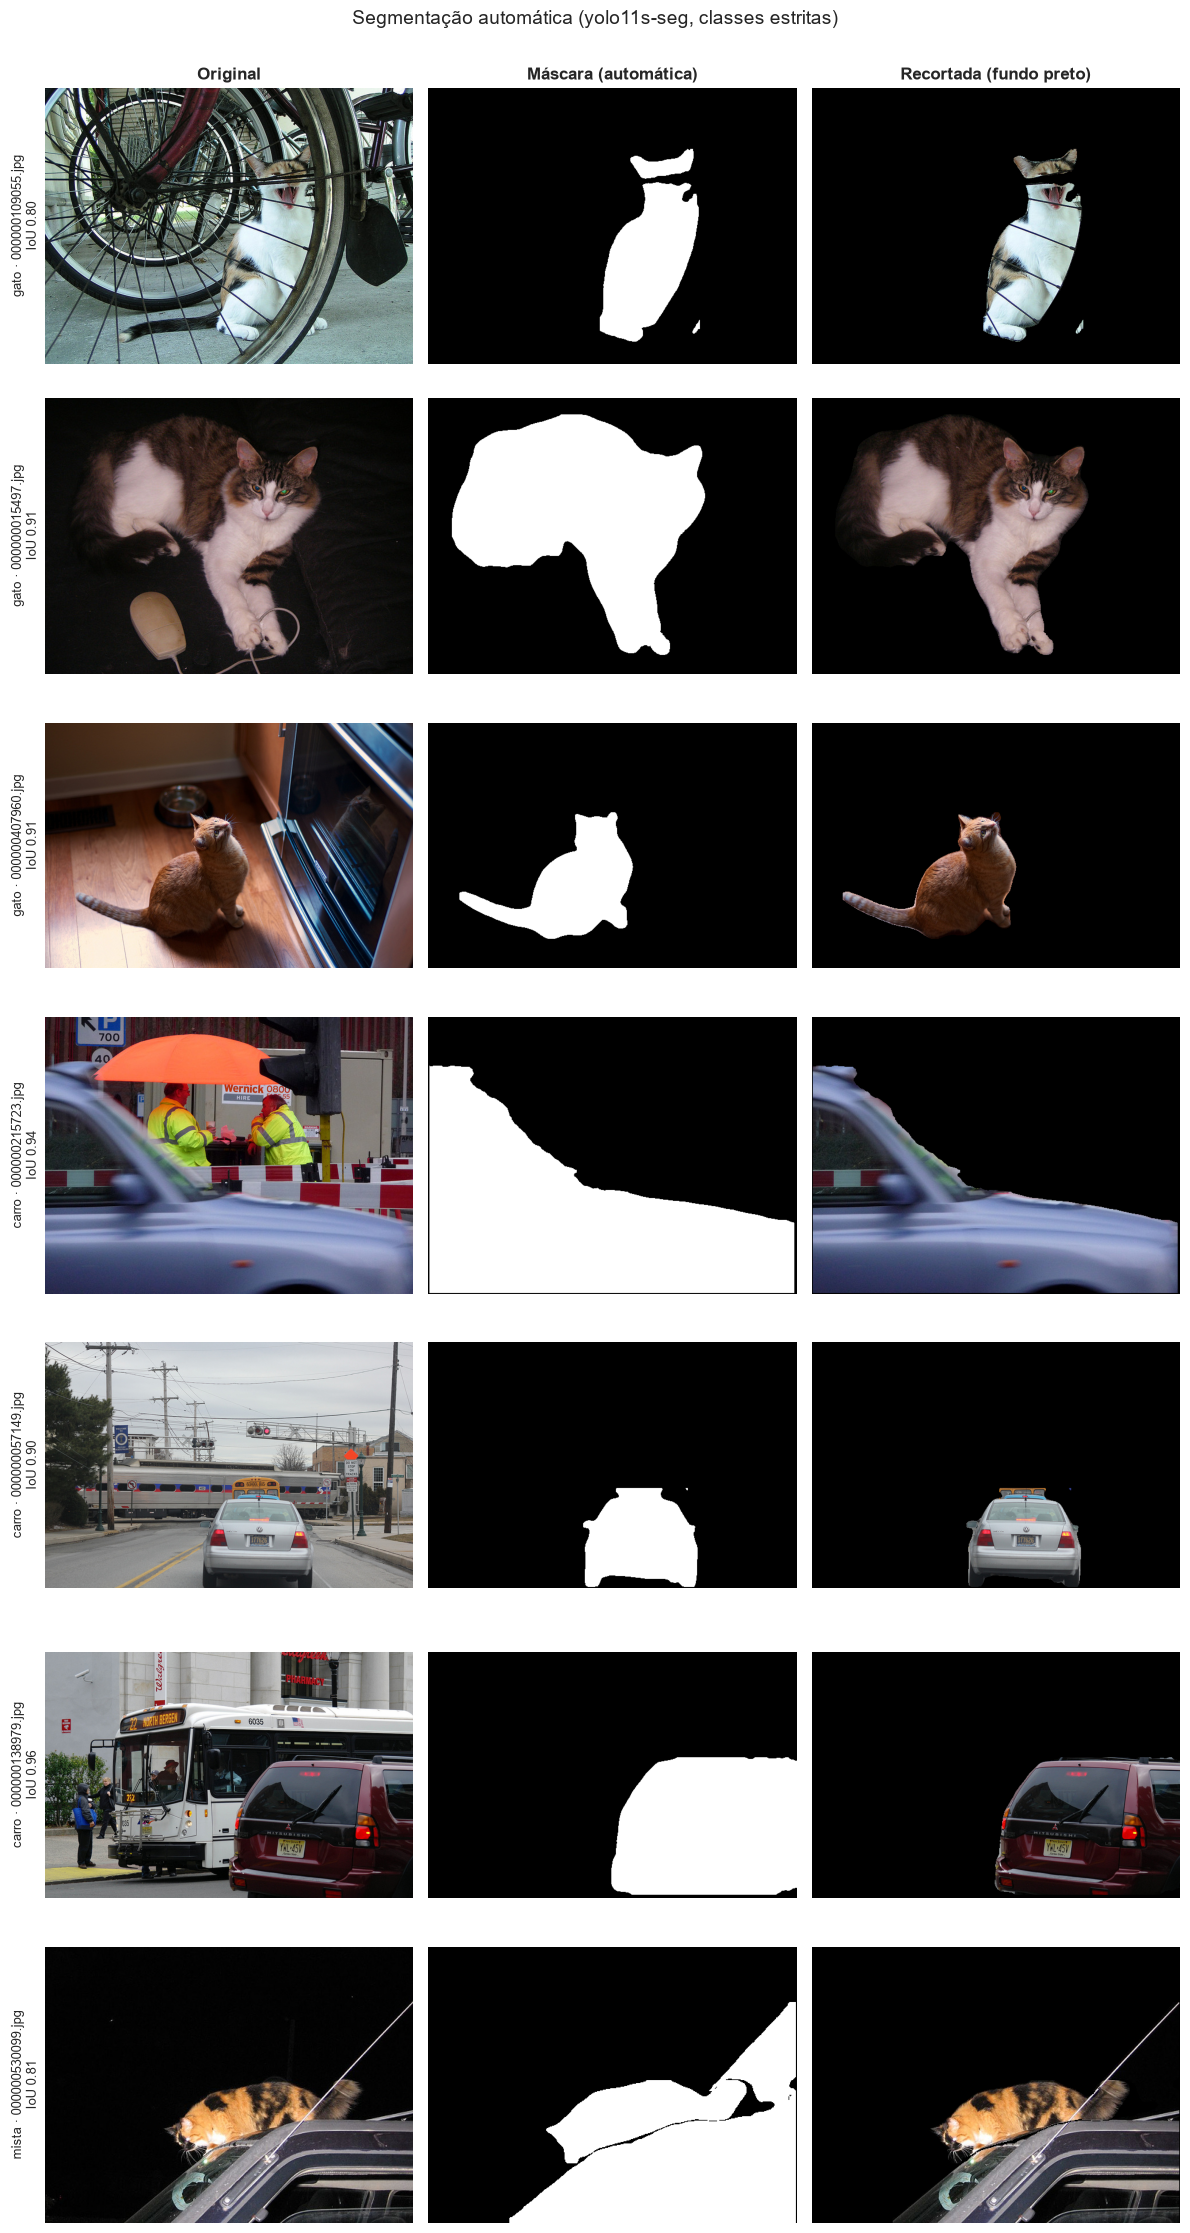

In [6]:
# ---------------- Grade exigida pelo enunciado ----------------
def item_grade(arquivo, rotulo):
    original = np.asarray(dados.abrir_imagem(config.IMAGENS_DIR / arquivo))
    caminho = pasta_mascaras / Path(arquivo).with_suffix(".png").name
    mascara = segmentacao.ler_mascara(caminho) if caminho.exists() else None
    recortada = np.asarray(dados.abrir_imagem(config.CONDICOES_DIR / "segmentada" / caminho.name))
    return {"titulo": rotulo, "original": original, "mascara": mascara, "recortada": recortada}

gerador = np.random.default_rng(config.SEED)
vitrine = tabela.merge(segmentos[["arquivo", "status", "iou"]], on="arquivo")
vitrine = vitrine[vitrine.conjunto.isin(["treino", "validacao"]) & vitrine.permite_derivados]
escolhidas = []
for grupo, n in (("gato", 3), ("carro", 3), ("mista", 1)):
    opcoes = vitrine[(vitrine.grupo == grupo) & (vitrine.status != "falha")].arquivo.tolist()
    escolhidas += [(a, grupo) for a in gerador.choice(opcoes, size=n, replace=False)]
itens = [item_grade(a, f"{g} · {a}\nIoU {vitrine.set_index('arquivo').iou[a]:.2f}") for a, g in escolhidas]
fig = vis.grade_segmentacao(itens, f"Segmentação automática ({ESCOLHA['segmentador']}, classes {ESCOLHA['classes']})")
vis.salvar(fig, "segmentacao_grade.png")
plt.show()

### 6.1 Figura do pipeline

Diagrama autoral das duas condições (O e S) usado no README, com as miniaturas de uma das imagens acima.

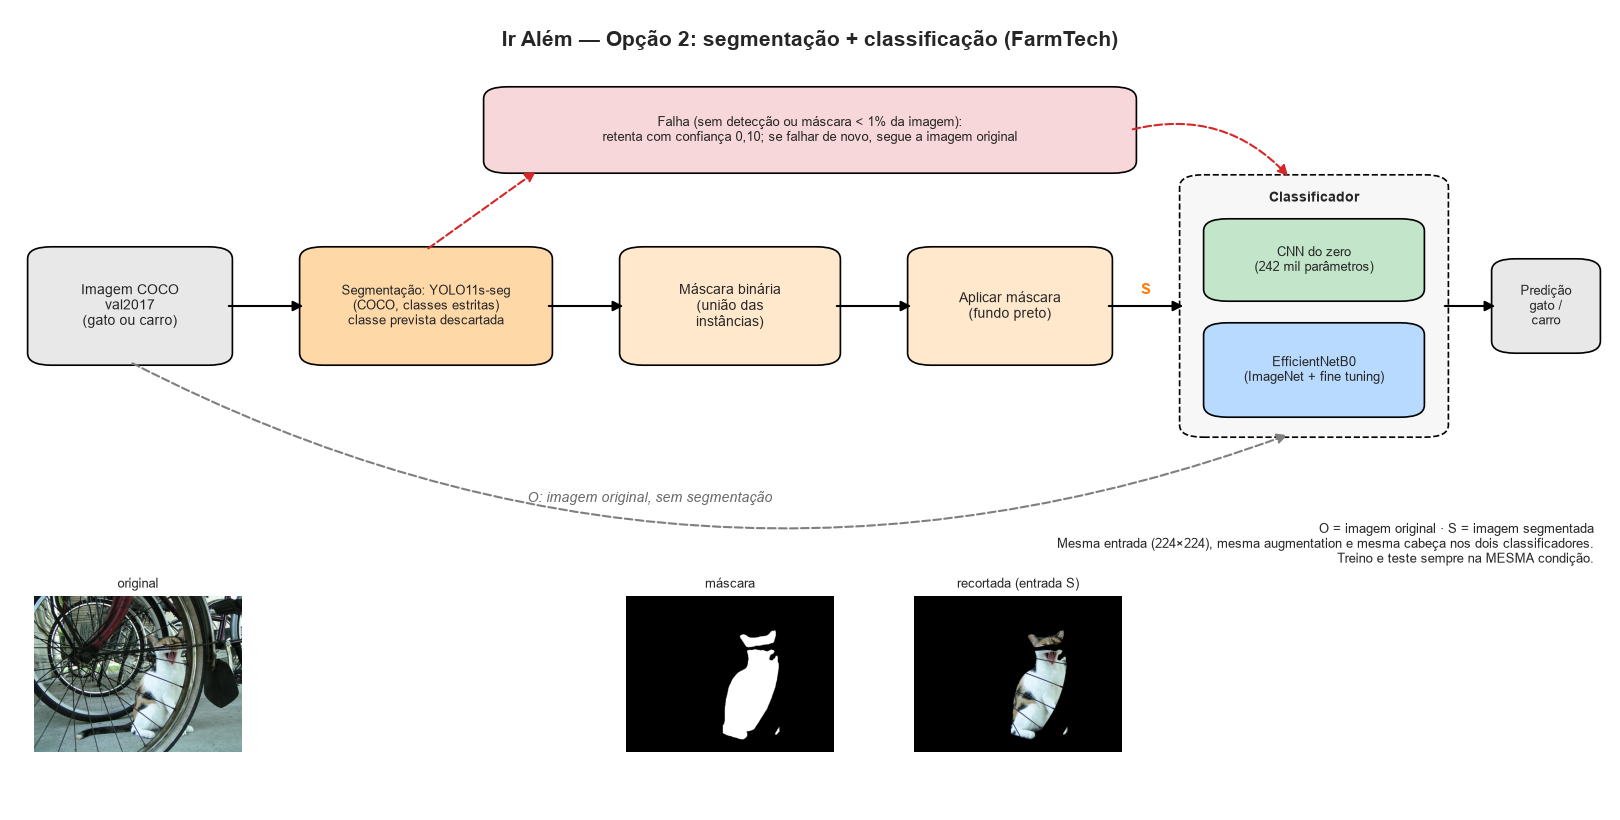

In [7]:
# ---------------- Figura autoral do pipeline ----------------
fig = vis.figura_pipeline({chave: itens[0][chave] for chave in ("original", "mascara", "recortada")},
                          segmentador=ESCOLHA["segmentador"], classes=ESCOLHA["classes"])
vis.salvar(fig, "pipeline.png")
plt.show()

## 7. Onde a segmentação erra

As três imagens de treino/validação com menor IoU (entre as de licença que permite obras derivadas): original,
máscara GT (referência humana do COCO) e máscara automática. Esses casos mostram os limites do pipeline; a lista
completa de falhas e de máscaras com IoU < 0,5 está na tabela da Seção 5.

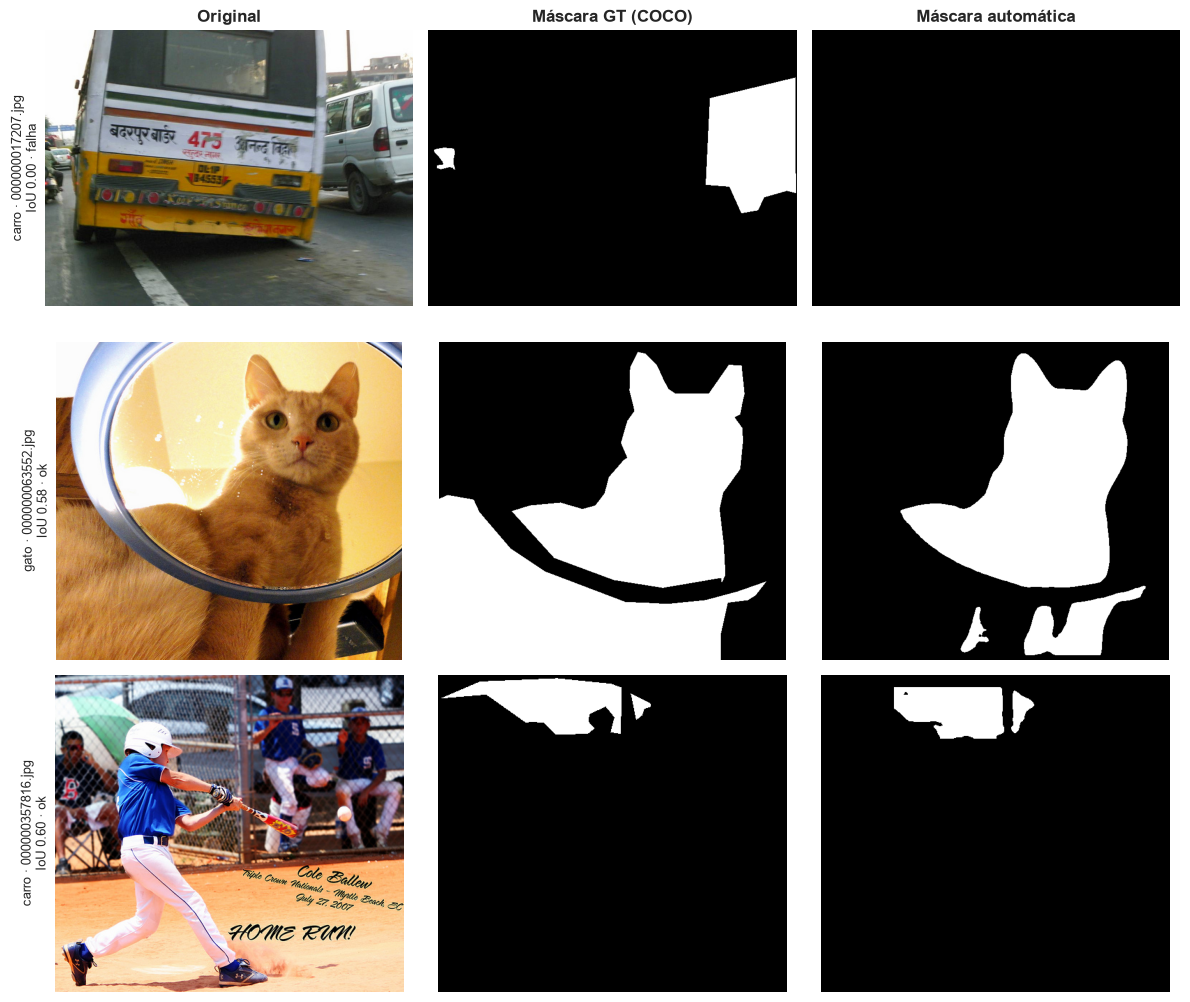

In [8]:
# ---------------- Piores casos (treino + validação) ----------------
piores = (segmentos.merge(tabela[["arquivo", "permite_derivados"]], on="arquivo")
          .query("conjunto in ['treino', 'validacao'] and permite_derivados").nsmallest(3, "iou"))
fig, eixos = plt.subplots(len(piores), 3, figsize=(12, 3.4 * len(piores)), squeeze=False)
for linha_ax, linha in zip(eixos, piores.itertuples()):
    item = item_grade(linha.arquivo, "")
    linha_ax[0].imshow(item["original"])
    linha_ax[0].set_ylabel(f"{linha.grupo} · {linha.arquivo}\nIoU {linha.iou:.2f} · {linha.status}", fontsize=9)
    linha_ax[1].imshow(GT[linha.arquivo], cmap="gray")
    linha_ax[2].imshow(item["mascara"] if item["mascara"] is not None else np.zeros_like(GT[linha.arquivo]), cmap="gray")
    for ax in linha_ax:
        ax.set_xticks([]); ax.set_yticks([])
for ax, titulo in zip(eixos[0], ["Original", "Máscara GT (COCO)", "Máscara automática"]):
    ax.set_title(titulo, fontweight="bold")
fig.tight_layout()
vis.salvar(fig, "segmentacao_piores_casos.png")
plt.show()

## 8. O segmentador sozinho já classifica?

Um segmentador treinado no COCO *sabe* o que é gato e o que é carro. Se ele acertar a classe sozinho, parte do
mérito da condição segmentada pode ser dele, e não do classificador. Por isso a classe prevista é descartada no
pipeline, e aqui medimos quanto ela acertaria: a imagem conta como acerto quando as classes-alvo detectadas são
exatamente a do grupo (mesmo critério da Entrega 2).

In [9]:
# ---------------- Acurácia implícita do segmentador ----------------
unica = segmentos[segmentos.grupo != "mista"].copy()
unica["acerto_implicito"] = unica.classes_detectadas == unica.grupo
implicita = unica.groupby("conjunto").acerto_implicito.agg(["sum", "size"])
implicita["acurácia implícita"] = (implicita["sum"] / implicita["size"]).round(3)
implicita.to_csv(config.RESULTADOS_DIR / "segmentacao_como_classificador.csv")
display(implicita.rename(columns={"sum": "acertos", "size": "imagens"}))

,acertos,imagens,acurácia implícita
conjunto,,,
teste_ampliado,49,52,0.942
teste_original,8,8,1.000
treino,60,64,0.938
validacao,7,8,0.875


## 9. Atalho da área da máscara

Depois de apagar o fundo, a quantidade de pixels pretos depende da classe: gatos ocupam mais da foto que carros.
Um classificador pode aprender o "tamanho da mancha" em vez da aparência. Medimos esse atalho com um classificador
trivial que só vê a **fração visível** da imagem que o classificador S recebe (a área da máscara, ou 1,0 quando a
segmentação falhou e a imagem original foi usada): um único limiar, escolhido para acertar o máximo no treino.

C:\Users\leonardo.souza\AppData\Local\Temp\ipykernel_86676\1355839017.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(dados_box, tick_labels=config.CLASSES, vert=False)


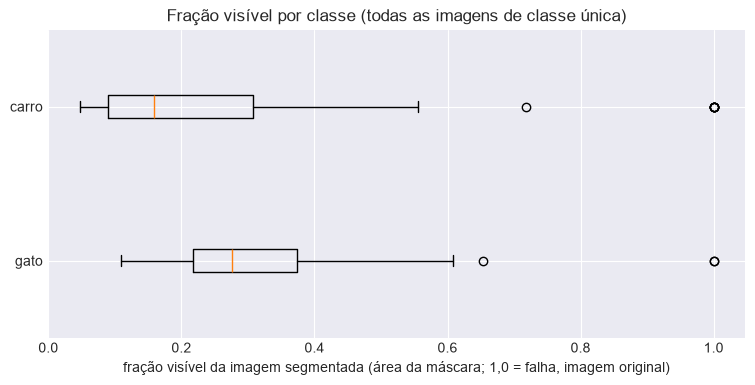

Regra aprendida no treino: carro se a fração visível for < 0.105


,imagens,acurácia só pela área,falhas de segmentação
conjunto,,,
treino,64,0.688,5
validacao,8,0.875,0
teste_original,8,0.625,0
teste_ampliado,52,0.673,3


In [10]:
# ---------------- Distribuição da área e baseline "só área" ----------------
fig, ax = plt.subplots(figsize=(9, 4))
dados_box = [unica[(unica.grupo == g)].fracao_visivel for g in config.CLASSES]
ax.boxplot(dados_box, tick_labels=config.CLASSES, vert=False)
ax.set_xlabel("fração visível da imagem segmentada (área da máscara; 1,0 = falha, imagem original)")
ax.set_title("Fração visível por classe (todas as imagens de classe única)")
vis.salvar(fig, "segmentacao_area_por_classe.png")
plt.show()

treino_area = unica[unica.conjunto == "treino"]
limiar, carro_abaixo = metricas.limiar_por_area(treino_area.fracao_visivel, treino_area.grupo.eq("carro").astype(int))
print(f"Regra aprendida no treino: carro se a fração visível for {'<' if carro_abaixo else '>='} {limiar:.3f}")
linhas = []
for conjunto in ("treino", "validacao", "teste_original", "teste_ampliado"):
    alvo = unica[unica.conjunto == conjunto]
    previsto = metricas.prever_por_area(alvo.fracao_visivel, limiar, carro_abaixo)
    acertos = previsto == alvo.grupo.eq("carro").astype(int).to_numpy()
    linhas.append({"conjunto": conjunto, "imagens": len(alvo), "acurácia só pela área": round(acertos.mean(), 3),
                   "falhas de segmentação": int((alvo.status == "falha").sum())})
baseline = pd.DataFrame(linhas).set_index("conjunto")
baseline.to_csv(config.RESULTADOS_DIR / "baseline_area.csv")
display(baseline)

## 10. Latência da segmentação

Tempo por imagem (segmentação + aplicação da máscara), uma imagem por vez, após aquecimento. No notebook 03, o
pipeline completo (segmentação + classificação) é medido ponta a ponta.

In [11]:
# ---------------- Latência ----------------
imagens_lat = [dados.abrir_imagem(config.IMAGENS_DIR / a)
               for a in tabela[tabela.conjunto == "teste_ampliado"].arquivo[:18]]
def segmentar_e_apagar(img):
    r = segmentacao.segmentar(seg, img)
    return segmentacao.aplicar_mascara(np.asarray(img), r.mascara) if r.mascara is not None else np.asarray(img)
media, desvio = metricas.medir_latencia(segmentar_e_apagar, imagens_lat, repeticoes=3)
dispositivo = AMBIENTE.get("gpu_nome", "CPU") if AMBIENTE.get("gpu_torch") else "CPU"
latencia_seg = pd.DataFrame([{"segmentador": ESCOLHA["segmentador"], "ms/img": round(media, 1),
                              "desvio": round(desvio, 1), "dispositivo": dispositivo}])
latencia_seg.to_csv(config.RESULTADOS_DIR / "latencia_segmentacao.csv", index=False)
display(latencia_seg)

,segmentador,ms/img,desvio,dispositivo
0,yolo11s-seg,365.7,77.3,CPU


## 11. Ablação: YOLO da Entrega 1 → SAM 2.1

A opção (b') reaproveita o detector da Entrega 1 (YOLOv5s customizado, 60 épocas) para gerar caixas que viram
prompts do SAM 2.1. O problema metodológico: esse detector foi **treinado nas 67 imagens de treino**, então deve
achar caixas melhores no treino do que no teste, e o classificador "segmentado" seria treinado com recortes mais
limpos do que os que verá no teste. Esta seção mede essa diferença.

Os pesos da Entrega 1 ficaram no Drive de quem a executou. Se `FARMTECH_PESOS_E1` apontar para eles, são usados;
senão o detector é **retreinado** exatamente como na Entrega 1 (repositório clássico no commit `f9578796`, 60
épocas, 640 px, batch 16, seed 42). O treino em GPU não é determinístico: o modelo retreinado é equivalente, não idêntico.

> **Requer GPU (ou os pesos originais).** O `train.py` do YOLOv5 liga o modo determinístico do PyTorch, que em CPU usa
> implementações seriais: na execução de referência um lote de 16 imagens levou ~4,5 min (~1 dia para as 60 épocas).
> No Colab com T4 o retreino leva ~3 min (Entrega 1). Sem GPU e sem `FARMTECH_PESOS_E1`, esta seção é pulada.

In [12]:
# ---------------- Detector da Entrega 1 (pesos existentes ou retreino) ----------------
PESOS_E1 = Path(os.environ.get("FARMTECH_PESOS_E1", config.MODELOS_DIR / "entrega1_yolov5s_60ep_best.pt"))
EXECUTAR_ABLACAO_E1 = PESOS_E1.exists() or AMBIENTE.get("gpu_torch", False)   # em CPU o retreino levaria ~1 dia
if not EXECUTAR_ABLACAO_E1:
    print("⏭️  Ablação da Entrega 1 não executada: sem GPU e sem os pesos originais (defina FARMTECH_PESOS_E1). "
          "No Colab com T4 o retreino leva ~3 min.")
# No Colab o repositório e o treino ficam no disco local (mais rápido que o Drive); só o best.pt vai para o Drive
TRABALHO_E1 = Path("/content/entrega1") if NO_COLAB else config.DADOS_DIR / "entrega1"
YOLOV5_DIR = TRABALHO_E1 / "yolov5"

def preparar_yolov5():
    """Clona o repositório clássico e garante o mesmo commit usado na Entrega 1."""
    if not (YOLOV5_DIR / ".git").exists():
        shutil.rmtree(YOLOV5_DIR, ignore_errors=True)
        subprocess.run(["git", "clone", "-q", "https://github.com/ultralytics/yolov5", str(YOLOV5_DIR)], check=True)
    subprocess.run(["git", "-C", str(YOLOV5_DIR), "checkout", "-q", "f9578796"], check=True)
    commit = subprocess.run(["git", "-C", str(YOLOV5_DIR), "rev-parse", "--short=8", "HEAD"],
                            capture_output=True, text=True).stdout.strip()
    assert commit == "f9578796", f"yolov5 no commit {commit}, esperado f9578796"
    # Mesmo passo da Entrega 1 (sem -U: pacotes já instalados, como o torch, não são trocados)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(YOLOV5_DIR / "requirements.txt")], check=True)

def retreinar_entrega1():
    """Mesmo dataset (67 treino / 9 validação, rótulos do repositório) e mesmos hiperparâmetros da Entrega 1."""
    base = TRABALHO_E1 / "dataset_yolo"
    for origem, destino in (("treino", "train"), ("validacao", "val")):
        (base / "images" / destino).mkdir(parents=True, exist_ok=True)
        (base / "labels" / destino).mkdir(parents=True, exist_ok=True)
        for arquivo in tabela[tabela.divisao == origem].arquivo:
            shutil.copy(config.IMAGENS_DIR / arquivo, base / "images" / destino / arquivo)
        for rotulo in (REPO_DIR / "dataset" / "labels" / origem).glob("*.txt"):
            shutil.copy(rotulo, base / "labels" / destino / rotulo.name)
    yaml_path = base / "farmtech.yaml"
    yaml_path.write_text(f"path: {base.as_posix()}\ntrain: images/train\nval: images/val\n\nnames:\n  0: gato\n  1: carro\n")
    comando = [sys.executable, "train.py", "--img", "640", "--batch", "16", "--epochs", "60", "--data", str(yaml_path),
               "--weights", "yolov5s.pt", "--seed", "42", "--name", "entrega1", "--exist-ok", "--cache",
               "--project", str(TRABALHO_E1 / "runs")]
    if not AMBIENTE.get("gpu_torch"):
        comando += ["--device", "cpu", "--workers", "0"]
    inicio = time.perf_counter()
    subprocess.run(comando, cwd=YOLOV5_DIR, check=True, env={**os.environ, "WANDB_MODE": "disabled"})
    shutil.copy(TRABALHO_E1 / "runs" / "entrega1" / "weights" / "best.pt", PESOS_E1)
    print(f"⏱️  Retreino da Entrega 1: {time.perf_counter() - inicio:.0f} s")

if EXECUTAR_ABLACAO_E1:
    preparar_yolov5()
    if not PESOS_E1.exists():
        retreinar_entrega1()
    print("Pesos da Entrega 1:", PESOS_E1)

⏭️  Ablação da Entrega 1 não executada: sem GPU e sem os pesos originais (defina FARMTECH_PESOS_E1). No Colab com T4 o retreino leva ~3 min.


In [13]:
# ---------------- IoU por conjunto: detector da Entrega 1 x segmentador escolhido ----------------
if EXECUTAR_ABLACAO_E1:
    seg_e1 = segmentacao.SegmentadorEntrega1(PESOS_E1, YOLOV5_DIR)
    linhas = []
    for linha in tabela.itertuples():
        r = segmentacao.segmentar(seg_e1, dados.abrir_imagem(config.IMAGENS_DIR / linha.arquivo))
        mascara = r.mascara if r.mascara is not None else np.zeros_like(GT[linha.arquivo])
        linhas.append({"arquivo": linha.arquivo, "conjunto": linha.conjunto, "status": r.status,
                       "iou": segmentacao.iou(mascara, GT[linha.arquivo])})
    e1 = pd.DataFrame(linhas)
    e1.to_csv(config.RESULTADOS_DIR / "ablacao_entrega1_sam.csv", index=False)
    ordem = ["treino", "validacao", "teste_original", "teste_ampliado"]
    comparacao = pd.DataFrame({
        "E1 → SAM 2.1: IoU médio": e1.groupby("conjunto").iou.mean(),
        "E1 → SAM 2.1: falhas": e1.groupby("conjunto").status.apply(lambda s: (s == "falha").sum()),
        f"{ESCOLHA['segmentador']}: IoU médio": segmentos.groupby("conjunto").iou.mean(),
        f"{ESCOLHA['segmentador']}: falhas": segmentos.groupby("conjunto").status.apply(lambda s: (s == "falha").sum()),
    }).loc[ordem].round(3)
    comparacao.to_csv(config.RESULTADOS_DIR / "ablacao_entrega1_resumo.csv")
    display(comparacao)

In [14]:
# ---------------- Exporta os CSVs para o repositório ----------------
arquivos = sorted(a.name for a in config.RESULTADOS_DIR.glob("*.csv")
                  if a.name.startswith(("segmentacao", "baseline_area", "latencia_segmentacao", "ablacao_entrega1")))
ambiente.exportar(arquivos + ["segmentador_escolhido.json"], AMBIENTE, "ambiente_02.json")

✅ Resultados copiados para C:\Users\leonardo.souza\Workspace\FarmTech - Fase 6\fiap-farmtech_solutions-fase06\ir_alem_opcao2\resultados


## 12. Conclusões da etapa

- **Rede escolhida:** YOLO11s-seg com as classes estritas {cat, car} teve o maior IoU médio no treino + validação
  (0,805). Refinar as caixas do YOLO26n-seg com o SAM 2.1 não superou (0,791) e custou ~15× mais tempo por imagem em
  CPU. O conjunto amplo de classes reduz as falhas (de 5 para 0 no YOLO11s-seg e de 6 para 4 nos outros dois), mas
  piora o IoU (0,68 a 0,71), porque põe na máscara outros veículos e animais da cena.
- **Falhas:** 8 de 137 imagens (5,8%) ficaram sem máscara e seguem como originais, 3 delas no teste ampliado (2 carros e
  1 gato). Elas são mais comuns em carros (4 de 32 no treino), em geral pequenos ou cortados. Outras 5 imagens têm
  máscara, mas com IoU < 0,5 (ex.: na mista `000000107087.jpg` a máscara automática cobre 93,5% da foto e a de
  referência, 19,5%).
- **Qualidade:** no teste ampliado, o IoU médio contra a máscara humana do COCO é 0,84 nos gatos e 0,76 nos carros
  (medianas de 0,93 e 0,90).
- **O segmentador sozinho já classifica:** pelas classes que detecta, ele acertaria 94,2% do teste ampliado. A classe
  prevista é descartada no pipeline, mas esse número mostra que, para objetos do COCO, ele faz boa parte do trabalho.
- **Atalho da área:** a regra "carro se a fração visível for < 0,105", aprendida só no treino, acerta 67,3% do teste
  ampliado. O tamanho da mancha carrega informação de classe; o notebook 03 compara esse valor com os classificadores.
- **Custo:** 366 ms por imagem em CPU para segmentar e apagar o fundo.
- **Ablação da Entrega 1 → SAM 2.1:** não executada nesta execução de referência, que roda em CPU (ver Seção 11). Ela
  está implementada para rodar no Colab com GPU ou com os pesos originais, mas não foi testada de ponta a ponta.